Порог покрытия затрат на поддержание (15*N >= 2 000 000): 133,334 чел.
Месяцев до 133,334 чел. при росте 3%/мес.: 112 мес.
Базовый сценарий (36 мес.): N_36 = 14,491 чел., V(N_36) = 1,050,002 руб., R_36 = 217,371 руб., NPV = -60,099,621.18 руб.
Пессимистичный (2%/10%): NPV = -59,086,830.45 руб.
Оптимистичный (5%/20%): NPV = -63,739,311.88 руб.
Минимальный ARPU для NPV >= 0 (36 мес., 3%/мес.): 242.55 руб./мес.


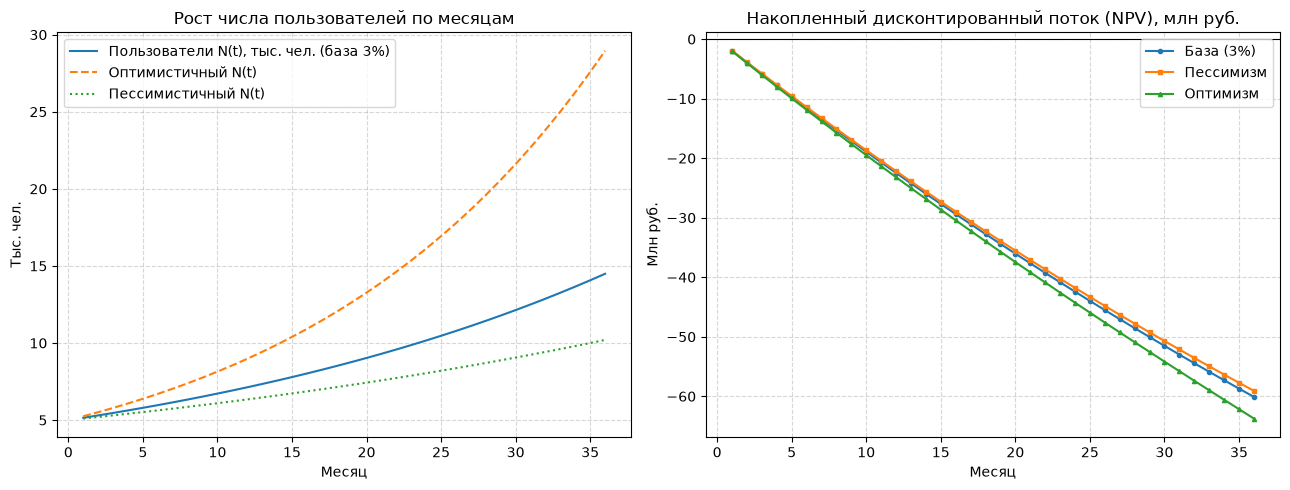

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. ИСХОДНЫЕ ДАННЫЕ
# ==========================================
M = 1_000_000  # потенциал рынка, чел.[cite: 6]
N0 = 5_000  # начальное число пользователей, чел.[cite: 6]
g_low = 0.03  # рост до критической массы (3%/мес.)[cite: 6]
g_high = 0.15  # рост после критической массы (15%/мес.)[cite: 6]
k = 0.005  # коэффициент ценности сети (руб./пользователь^2)[cite: 6]
maint_cost = 2_000_000  # затраты на поддержание в мес., руб.[cite: 6]
cac = 500  # стоимость привлечения пользователя, руб.[cite: 6]
arpu = 15  # средний доход с пользователя в мес., руб.[cite: 6]
months = 36  # горизонт оценки, мес.[cite: 6]
r_month = 0.01  # ставка дисконтирования в мес. (12% годовых / 12)[cite: 6]


def simulate(g_before, g_after, arpu_val=arpu, n_switch=None, n_months=months):
  n_prev = float(N0)
  N_series, V_series, R_series, profit_series, pv_series, new_u_series = (
      [],
      [],
      [],
      [],
      [],
      [],
  )
  for t in range(1, n_months + 1):
    g = g_after if (n_switch is not None and n_prev >= n_switch) else g_before
    n_curr = min(float(M), n_prev * (1.0 + g))
    new_u = n_curr - n_prev
    v_t = k * (n_curr**2)
    r_t = arpu_val * n_curr
    p_t = r_t - maint_cost - cac * new_u
    pv_t = p_t / ((1.0 + r_month) ** t)

    N_series.append(n_curr)
    V_series.append(v_t)
    R_series.append(r_t)
    profit_series.append(p_t)
    pv_series.append(pv_t)
    new_u_series.append(new_u)
    n_prev = n_curr

  return {
      "N": N_series,
      "V": V_series,
      "R": R_series,
      "profit": profit_series,
      "pv": pv_series,
      "new_u": new_u_series,
      "npv": sum(pv_series),
      "cum_profit": np.cumsum(profit_series),
      "cum_pv": np.cumsum(pv_series),
  }


# ==========================================
# 2. КРИТИЧЕСКАЯ МАССА, СЦЕНАРИИ И ARPU
# ==========================================
n_maint_breakeven = math.ceil(maint_cost / arpu)  # 133 334 чел. (R >= maint)
months_to_133k_at_3p = math.ceil(
    math.log(n_maint_breakeven / N0) / math.log(1 + g_low)
)

base = simulate(g_low, g_high)
pess = simulate(0.02, 0.10)
opt = simulate(0.05, 0.20)

# Минимальный ARPU для NPV >= 0 за 36 мес. при базовом росте g_low:
disc_factors = [(1.0 + r_month) ** t for t in range(1, months + 1)]
denom_arpu = sum(base["N"][i] / disc_factors[i] for i in range(months))
numer_arpu = sum(
    (maint_cost + cac * base["new_u"][i]) / disc_factors[i]
    for i in range(months)
)
min_arpu_npv0 = numer_arpu / denom_arpu

print(
    f"Порог покрытия затрат на поддержание (15*N >= 2 000 000): {n_maint_breakeven:,} чел."
)
print(
    f"Месяцев до {n_maint_breakeven:,} чел. при росте 3%/мес.: {months_to_133k_at_3p} мес."
)
print(
    f"Базовый сценарий (36 мес.): N_36 = {base['N'][-1]:,.0f} чел., "
    f"V(N_36) = {base['V'][-1]:,.0f} руб., R_36 = {base['R'][-1]:,.0f} руб., "
    f"NPV = {base['npv']:,.2f} руб."
)
print(f"Пессимистичный (2%/10%): NPV = {pess['npv']:,.2f} руб.")
print(f"Оптимистичный (5%/20%): NPV = {opt['npv']:,.2f} руб.")
print(
    f"Минимальный ARPU для NPV >= 0 (36 мес., 3%/мес.): {min_arpu_npv0:,.2f} руб./мес."
)

# ==========================================
# 3. ГРАФИКИ И СОХРАНЕНИЕ В PNG
# ==========================================
t_axis = np.arange(1, months + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(
    t_axis,
    np.array(base["N"]) / 1e3,
    label="Пользователи N(t), тыс. чел. (база 3%)",
)
ax1.plot(
    t_axis, np.array(opt["N"]) / 1e3, linestyle="--", label="Оптимистичный N(t)"
)
ax1.plot(
    t_axis, np.array(pess["N"]) / 1e3, linestyle=":", label="Пессимистичный N(t)"
)
ax1.set_title("Рост числа пользователей по месяцам")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Тыс. чел.")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(
    t_axis, base["cum_pv"] / 1e6, marker="o", markersize=3, label="База (3%)"
)
ax2.plot(
    t_axis, pess["cum_pv"] / 1e6, marker="s", markersize=3, label="Пессимизм"
)
ax2.plot(
    t_axis, opt["cum_pv"] / 1e6, marker="^", markersize=3, label="Оптимизм"
)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Накопленный дисконтированный поток (NPV), млн руб.")
ax2.set_xlabel("Месяц")
ax2.set_ylabel("Млн руб.")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("social_network_crm_charts.png", dpi=300, bbox_inches="tight")
plt.show()